In [208]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

DERIVED = Path("derived")
VISUALIZATIONS = Path("visualizations/coefficients")
%config InlineBackend.figure_format = 'retina'
plt.rcParams['savefig.dpi'] = 300

In [167]:
data = pd.read_csv(DERIVED / 'data24-26.csv')

In [176]:
# Sign pitcher_break_x correctly (pitcher_break_x is unsigned; see movement_plot in Visualizations.ipynb)
league_arm = np.where(data['league_break_x'] < 0, 1, -1)
league_arm = np.where(data['league_break_x'].isna(), 1, league_arm)  # forkballs have no league avg: arm side
toward_league = data['league_break_x'].abs() + data['diff_x']
same_side = np.where(toward_league.isna() | (toward_league >= 0), 1, -1)

# Arm side = +, glove side = -. Same meaning for RHP and LHP, so use this in the models.
data['break_x_arm'] = data['pitcher_break_x'] * league_arm * same_side
# Pitcher's view (3B = +), matches the movement plots. A RHP's arm side is +x, a LHP's is -x.
data['break_x_plot'] = data['break_x_arm'] * np.where(data['hand'] == 'R', 1, -1)

data['euclid_dist'] = np.sqrt(data['pitcher_break_z_induced']**2 + data['pitcher_break_x']**2)
data['movement_angle'] = np.arctan2(data['pitcher_break_z_induced'], data['break_x_arm'])


In [177]:
data.head(1)

,id,name,team,hand,year,pitch_type,pitch_type_qualified,n_pitches,pitch_usage,avg_speed,pitcher_break_x,pitcher_break_z_induced,run_value_per_100,run_value,n_ff,n_si,n_fc,n_sl,n_ch,n_cu,n_fs,n_kn,n_st,n_sv,team_id,ball_angle,relative_release_ball_x,release_ball_z,relative_shoulder_x,shoulder_z,total_pitches,pitches_per_game,pitch_per,pitcher_break_z,league_break_z,diff_z,rise,league_break_x,diff_x,tail,percent_rank_diff_z,percent_rank_diff_x,pa,ba,slg,woba,whiff_percent,k_percent,put_away,est_ba,est_slg,est_woba,hard_hit_percent,break_x_arm,break_x_plot,euclid_dist,movement_angle
0,657277,"Webb, Logan",SF,R,2024,SI,True,1270,39.7,92.6,15.1,1.1,1.4,17,5.5,39.7,2.6,NaN,30.9,NaN,NaN,NaN,21.3,NaN,137,22.1,-2.664236,4.978202,-0.514977,4.103699,3200,19.753086,0.396875,30.9,-25.4,5.5,22.0,-15.5,-0.3,-2.0,0.968858,0.346021,315,0.268,0.338,0.306,14.1,16.5,20.5,0.259,0.375,0.317,44.7,15.1,15.1,15.140013,0.072719


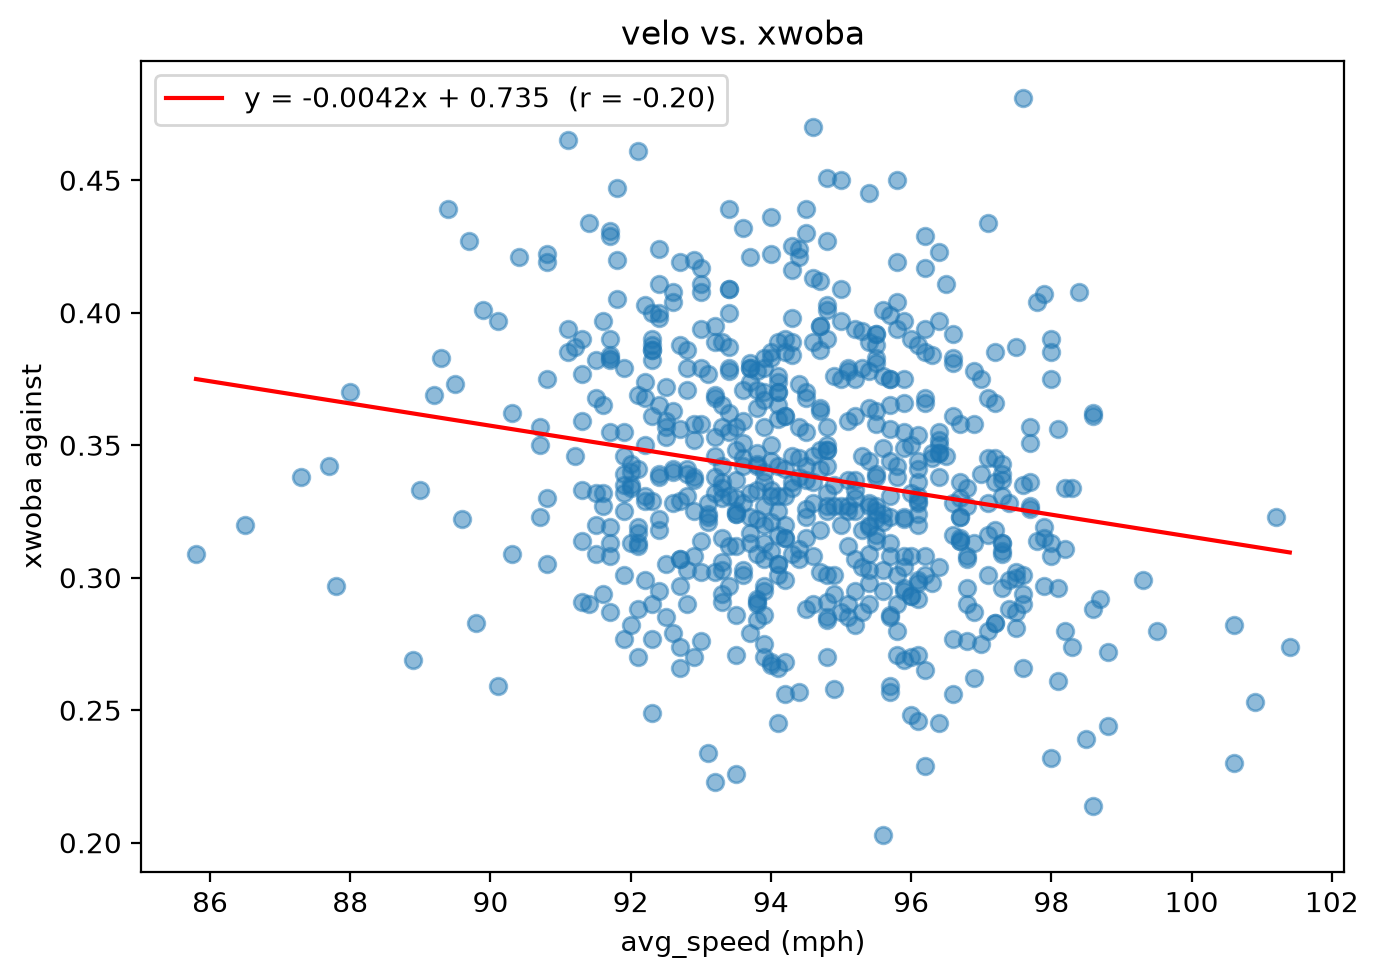

In [179]:
import numpy as np
import matplotlib.pyplot as plt

ff = data.loc[(data['pitch_type'] == 'FF')  &(data['pitch_type_qualified'] == True)]


fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ff['avg_speed'],ff['est_woba'], alpha=0.5)

m, b = np.polyfit(ff['avg_speed'], ff['est_woba'], 1)
xs = np.linspace(ff['avg_speed'].min(), ff['avg_speed'].max(), 100)
r = np.corrcoef(ff['avg_speed'], ff['est_woba'])[0, 1]
ax.plot(xs, m * xs + b, color='red', label=f'y = {m:.4f}x + {b:.3f}  (r = {r:.2f})')

ax.set_xlabel('avg_speed (mph)')
ax.set_ylabel('xwoba against')
ax.set_title('velo vs. xwoba')
ax.legend()
plt.tight_layout()
plt.show()

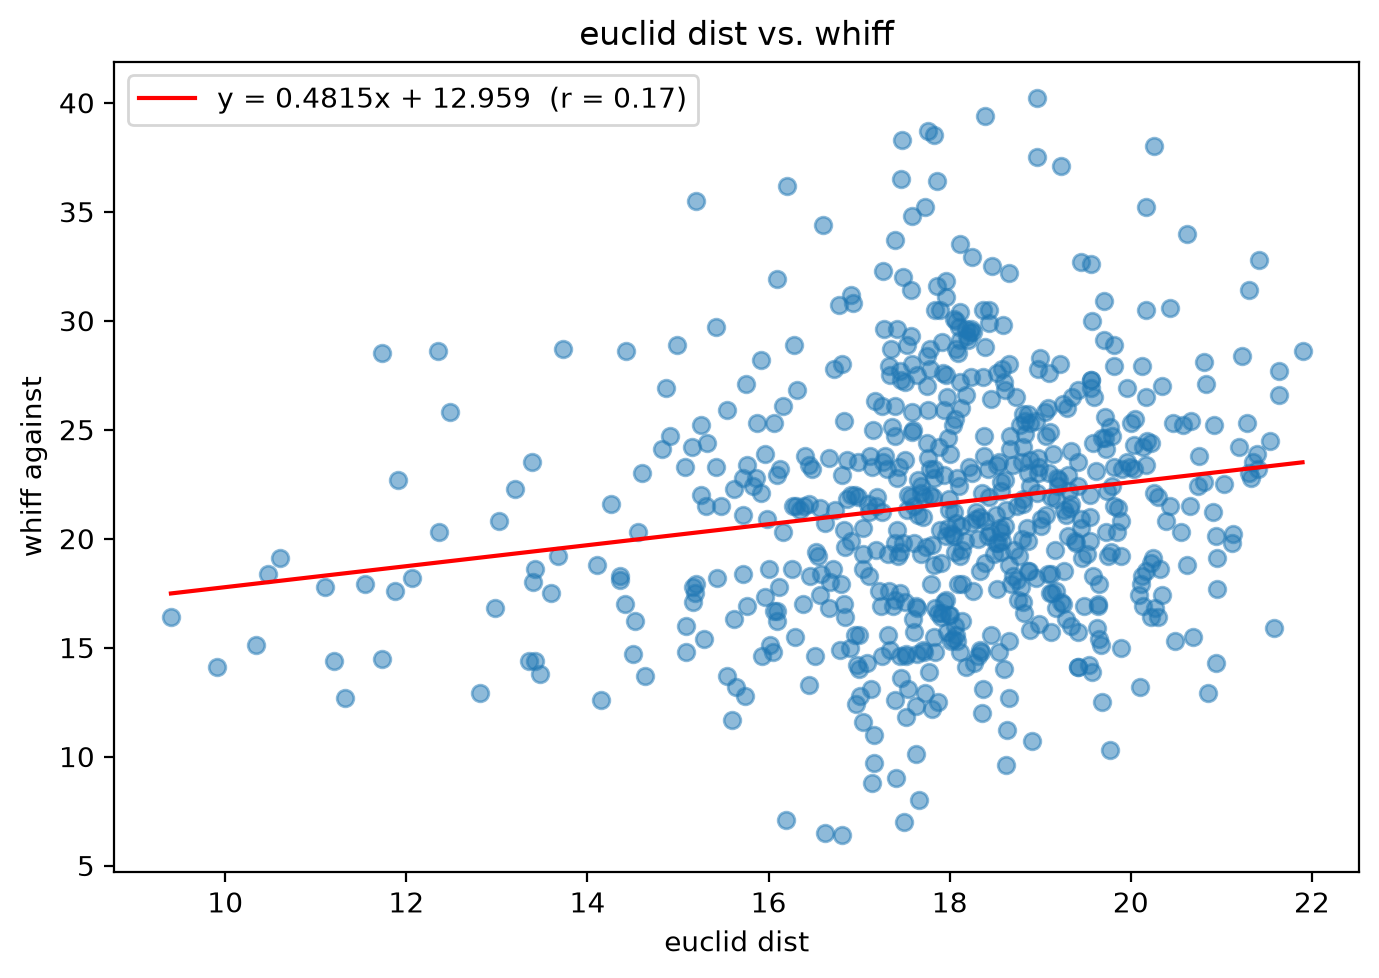

In [180]:
import numpy as np
import matplotlib.pyplot as plt

cb = data.loc[(data['pitch_type'] == 'FF') & (data['pitch_type_qualified'] == True)]


fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cb['euclid_dist'],cb['whiff_percent'], alpha=0.5)

m, b = np.polyfit(cb['euclid_dist'], cb['whiff_percent'], 1)
xs = np.linspace(cb['euclid_dist'].min(), cb['euclid_dist'].max(), 100)
r = np.corrcoef(cb['euclid_dist'], cb['whiff_percent'])[0, 1]
ax.plot(xs, m * xs + b, color='red', label=f'y = {m:.4f}x + {b:.3f}  (r = {r:.2f})')

ax.set_xlabel('euclid dist')
ax.set_ylabel('whiff against')
ax.set_title('euclid dist vs. whiff')
ax.legend()
plt.tight_layout()
plt.show()

In [182]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

#diff z and diff x are relative to comparable, within 2mph and 0.5 ft of extension/release

ff26 = data.loc[(data['pitch_type'] == 'FF') & (data['pitch_type_qualified'] == True) & (data['year']==2026)]
# model_raw_features = ['avg_speed','pitcher_break_x','pitcher_break_z_induced',]
model_raw_features = ['avg_speed', 'ball_angle', 'release_ball_z','movement_angle','euclid_dist']
#drops all rows not in the model raw features list or est woba
ff26_model_raw = ff26.dropna(subset=model_raw_features + ['whiff_percent'])
X = ff26_model_raw[model_raw_features]
y = ff26_model_raw['whiff_percent']


w = ff26_model_raw['pa']
model = make_pipeline(StandardScaler(), LinearRegression())
#weights by sample size when fitting
model.fit(X,y,linearregression__sample_weight=w)

weights = pd.Series(model[-1].coef_, index = model_raw_features).sort_values()
print("All weights are in standard deviations. So one standard deviation of something is associated with that many lower points in xwoba.")
print(weights)


rmse = -cross_val_score(model, X, y, cv = 5, scoring='neg_root_mean_squared_error', params={'linearregression__sample_weight':w}) #typical size of a miss, smaller is better

r2_in = model.score(X, y, sample_weight=w)
n, p = X.shape
r2_adj = 1 - (1 - r2_in) * (n - 1) / (n - p - 1)
print(f"Adjusted R^2: {r2_adj}")

print(f"cross validated typical miss is {round(rmse.mean(),4)} guessing average mean for every pitcher gives {round(y.std(),4)}")


All weights are in standard deviations. So one standard deviation of something is associated with that many lower points in xwoba.
ball_angle       -2.427594
release_ball_z   -1.127000
euclid_dist       1.794529
movement_angle    2.164710
avg_speed         2.706332
dtype: float64
Adjusted R^2: 0.35702630555122405
cross validated typical miss is 4.7928 guessing average mean for every pitcher gives 5.6228


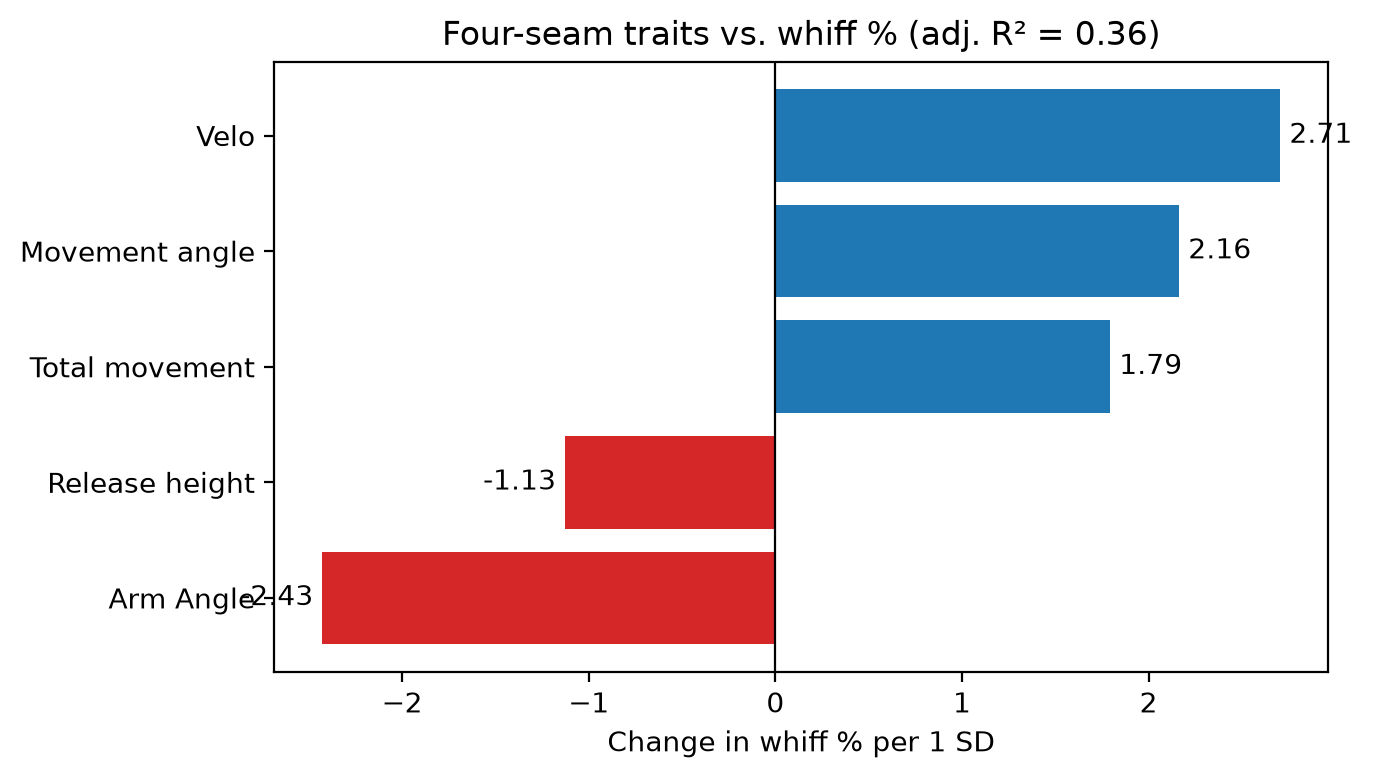

In [183]:
import matplotlib.pyplot as plt

labels = {
    'avg_speed': 'Velo',
    'ball_angle': 'Arm Angle',
    'release_ball_z': 'Release height',
    'movement_angle': 'Movement angle',
    'euclid_dist': 'Total movement',
}

weights = pd.Series(model[-1].coef_, index=model_raw_features).rename(labels).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['tab:blue' if c > 0 else 'tab:red' for c in weights]
ax.barh(weights.index, weights.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)

for i, c in enumerate(weights):
    ax.text(c, i, f' {c:.2f} ', va='center', ha='left' if c >= 0 else 'right')

ax.set_xlabel('Change in whiff % per 1 SD')
ax.set_title(f'Four-seam traits vs. whiff % (adj. R² = {r2_adj:.2f})')
plt.tight_layout()
plt.show()

In [184]:
#IVB and HB model

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

#diff z and diff x are relative to comparable, within 2mph and 0.5 ft of extension/release

ff26 = data.loc[(data['pitch_type'] == 'FF') & (data['pitch_type_qualified'] == True) & (data['year']==2026)]
model_raw_features = ['avg_speed','pitcher_break_x','ball_angle','release_ball_z','pitcher_break_z_induced',]
# model_raw_features = ['avg_speed', 'ball_angle', 'release_ball_z','movement_angle','euclid_dist']
#drops all rows not in the model raw features list or est woba
ff26_model_raw = ff26.dropna(subset=model_raw_features + ['est_woba'])
X = ff26_model_raw[model_raw_features]
y = ff26_model_raw['whiff_percent']


w = ff26_model_raw['pa']
model = make_pipeline(StandardScaler(), LinearRegression())
#weights by sample size when fitting
model.fit(X,y,linearregression__sample_weight=w)

weights = pd.Series(model[-1].coef_, index = model_raw_features).sort_values()
print("All weights are in standard deviations. So one standard deviation of something is associated with that many lower points in xwoba.")
print(weights)


rmse = -cross_val_score(model, X, y, cv = 5, scoring='neg_root_mean_squared_error', params={'linearregression__sample_weight':w}) #typical size of a miss, smaller is better

r2_in = model.score(X, y, sample_weight=w)
n, p = X.shape
r2_adj = 1 - (1 - r2_in) * (n - 1) / (n - p - 1)
print(f"Adjusted R^2: {r2_adj}")

print(f"cross validated typical miss is {round(rmse.mean(),4)} guessing average mean for every pitcher gives {round(y.std(),4)}")




All weights are in standard deviations. So one standard deviation of something is associated with that many lower points in xwoba.
ball_angle                -2.181758
release_ball_z            -1.242190
pitcher_break_x           -0.623660
pitcher_break_z_induced    1.880931
avg_speed                  2.656168
dtype: float64
Adjusted R^2: 0.3431070662585892
cross validated typical miss is 4.8418 guessing average mean for every pitcher gives 5.6228


In [185]:

# Standardize the same way StandardScaler does, so coefs match the sklearn weights
X_std = (X - X.mean()) / X.std(ddof=0)
X_sm = sm.add_constant(X_std)

wls = sm.WLS(y, X_sm, weights=w).fit(cov_type='HC3')  # robust SEs
print(wls.summary())

ci = wls.conf_int(alpha=0.05).drop('const')
ci.columns = ['lo', 'hi']
coefs = wls.params.drop('const')

                            WLS Regression Results                            
Dep. Variable:          whiff_percent   R-squared:                       0.359
Model:                            WLS   Adj. R-squared:                  0.343
Method:                 Least Squares   F-statistic:                     13.97
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           9.18e-12
Time:                        15:16:10   Log-Likelihood:                -629.98
No. Observations:                 212   AIC:                             1272.
Df Residuals:                     206   BIC:                             1292.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

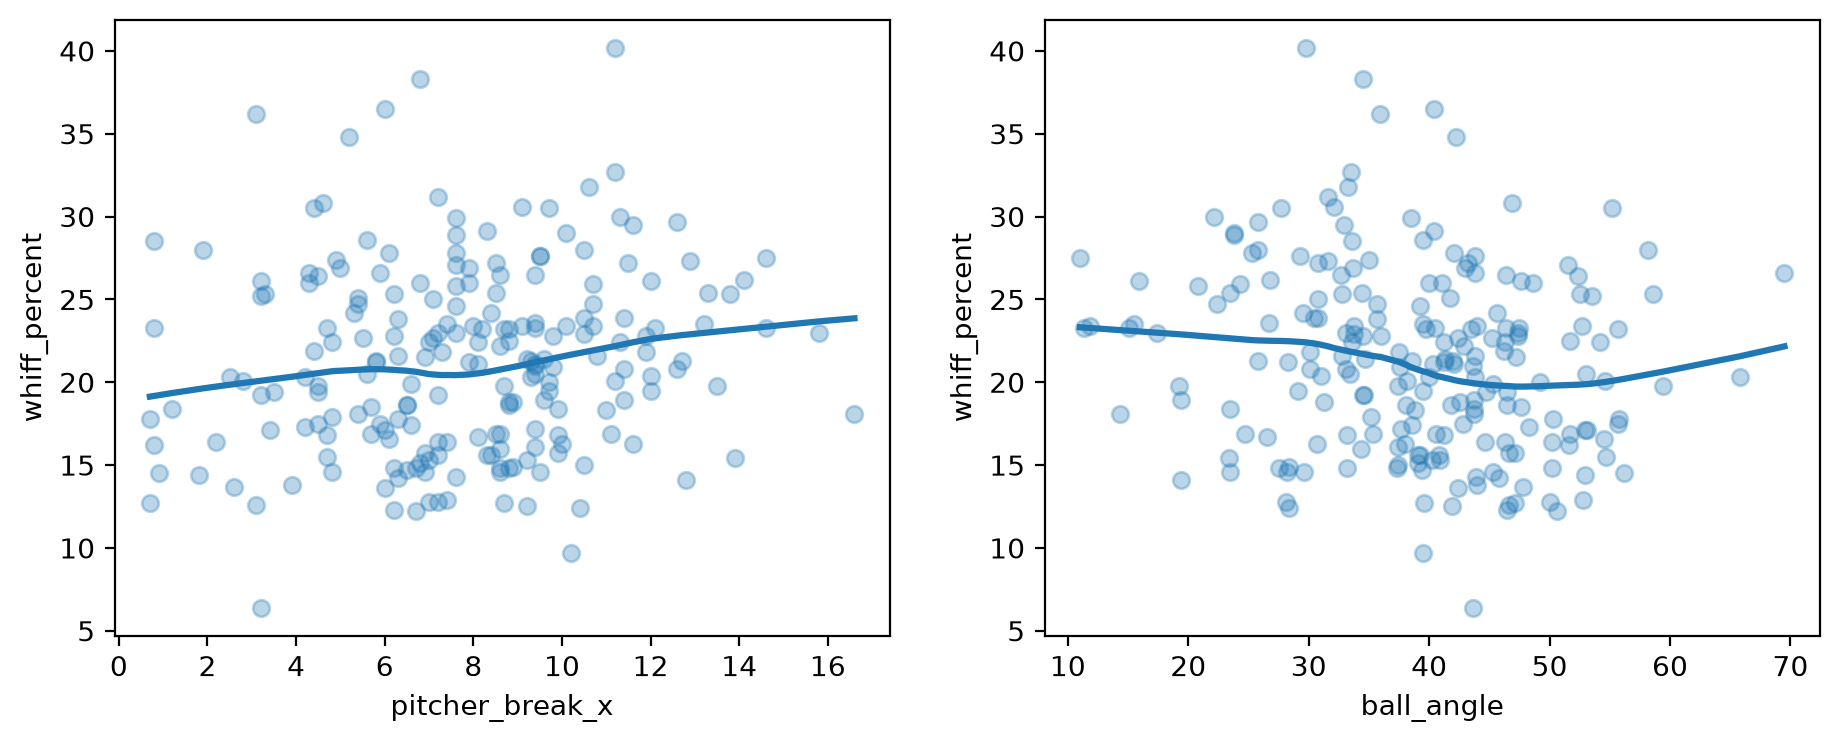

In [118]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.regplot(data=ff26_model_raw, x='pitcher_break_x', y='whiff_percent', lowess=True, scatter_kws={'alpha': 0.3}, ax=axes[0])
sns.regplot(data=ff26_model_raw, x='ball_angle', y='whiff_percent', lowess=True, scatter_kws={'alpha': 0.3}, ax=axes[1])
plt.show()

# Function which gives Coefficients with 95% CIs, by pitch type

In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

FEATURE_LABELS = {
    'avg_speed': 'Velocity',
    'ball_angle': 'Arm angle',
    'release_ball_z': 'Release height',
    'break_x_arm': 'Armside movement',
    'pitcher_break_z_induced': 'Vertical movement',
    'movement_angle': 'Movement angle',
    'euclid_dist': 'Total movement',
    'diff_x': 'Horiz. mvmt vs. comps',
    'diff_z': 'Vert. mvmt vs. comps',
}

TARGET_LABELS = {
    'whiff_percent': 'whiff %',
    'est_woba': 'xwOBA',
    'k_percent': 'K %',
    'hard_hit_percent': 'hard-hit %',
}


def fit_pitch_model(data, pitch_type, features, target='whiff_percent',
                    year=2026, weight='pa', cv=5, alpha=0.05, robust=True):
    """Weighted linear model of `target` on standardized `features` for one pitch type.

    year can be an int, a list of years, or None (all years pooled).
    Returns a dict with a coefficient table (coef + CI + p-value per 1 SD) and fit stats.
    """
    df = data.loc[(data['pitch_type'] == pitch_type) & (data['pitch_type_qualified'] == True)]
    if year is not None:
        years = [year] if np.isscalar(year) else list(year)
        df = df.loc[df['year'].isin(years)]
    df = df.dropna(subset=features + [target, weight])

    X, y, w = df[features], df[target], df[weight]
    n, p = X.shape
    if n <= p + 1:
        raise ValueError(f'{pitch_type} {year}: only {n} rows for {p} features')

    # Coefficients + CIs (statsmodels). Standardized like StandardScaler (ddof=0),
    # so the coefs are identical to the sklearn pipeline's.
    X_std = (X - X.mean()) / X.std(ddof=0)
    wls = sm.WLS(y, sm.add_constant(X_std), weights=w).fit(cov_type='HC3' if robust else 'nonrobust')
    ci = wls.conf_int(alpha=alpha)
    coefs = pd.DataFrame({
        'coef': wls.params,
        'ci_lo': ci[0],
        'ci_hi': ci[1],
        'p_value': wls.pvalues,
    }).drop('const')

    model = make_pipeline(StandardScaler(), LinearRegression())
    rmse = -cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error',
                            params={'linearregression__sample_weight': w})

    return {
        'pitch_type': pitch_type,
        'year': year,
        'target': target,
        'n': n,
        'coefs': coefs,
        'r2_adj': wls.rsquared_adj,
        'cv_rmse': rmse.mean(),
        'y_std': y.std(),
        'alpha': alpha,
        'wls': wls,
        'df': df,
    }


def plot_pitch_model(res, ax=None, labels=FEATURE_LABELS, save=None):
    """Horizontal bar chart of coefficients with CI error bars."""
    coefs = res['coefs'].rename(index=labels).sort_values('coef')
    err = [coefs['coef'] - coefs['ci_lo'], coefs['ci_hi'] - coefs['coef']]
    conf = int(round((1 - res['alpha']) * 100))
    target_name = TARGET_LABELS.get(res['target'], res['target'])

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 0.6 * len(coefs) + 1.5))
    colors = ['tab:blue' if c > 0 else 'tab:red' for c in coefs['coef']]
    ax.barh(coefs.index, coefs['coef'], color=colors, xerr=err, capsize=4, ecolor='black')
    ax.axvline(0, color='black', linewidth=0.8)

    for i, (c, lo, hi) in enumerate(zip(coefs['coef'], coefs['ci_lo'], coefs['ci_hi'])):
        x = hi if c >= 0 else lo
        ax.text(x, i, f' {c:.2f} ', va='center', ha='left' if c >= 0 else 'right')

    # leave room for the labels past the error bars
    lo, hi = coefs['ci_lo'].min(), coefs['ci_hi'].max()
    pad = 0.2 * (hi - lo)
    ax.set_xlim(min(lo, 0) - pad, max(hi, 0) + pad)

    year = res['year'] if res['year'] is not None else '2024-2026'
    ax.set_xlabel(f'Change in {target_name} per 1 SD ({conf}% CI)')
    ax.set_title(f"{res['pitch_type']} {year}: traits vs. {target_name} "
                 f"(adj. R² = {res['r2_adj']:.2f}, n = {res['n']})")
    plt.tight_layout()
    if save:
        ax.figure.savefig(save, bbox_inches='tight')
    return ax


def summarize(res):
    print(f"{res['pitch_type']} {res['year']} -> {res['target']}  (n = {res['n']})")
    print(res['coefs'].round(4))
    print(f"Adjusted R^2: {res['r2_adj']:.3f}")
    print(f"CV typical miss: {res['cv_rmse']:.4f}  vs. guessing the mean: {res['y_std']:.4f}\n")


def run_pitch_types(data, pitch_types, features, target='whiff_percent', year=2026,
                    min_n=40, plot=True, save_dir=None, **kwargs):
    """Fit + summarize + plot each pitch type. Skips types with fewer than min_n rows.
    Returns {pitch_type: result}."""
    results = {}
    for pt in pitch_types:
        try:
            res = fit_pitch_model(data, pt, features, target=target, year=year, **kwargs)
        except ValueError as e:
            print(f'Skipping {pt}: {e}')
            continue
        if res['n'] < min_n:
            print(f"Skipping {pt}: n = {res['n']} < {min_n}")
            continue
        results[pt] = res
        summarize(res)
        if plot:
            save = f'{save_dir}/{pt}_{year}_{target}_coefs.png' if save_dir else None
            plot_pitch_model(res, save=save)
            plt.savefig(VISUALIZATIONS / f'{res['pitch_type']}')
            plt.show()
    return results


def coef_table(results):
    """Long table of every pitch type's coefficients, for comparing across pitch types."""
    return pd.concat({pt: r['coefs'] for pt, r in results.items()}, names=['pitch_type', 'feature'])


FF None -> whiff_percent  (n = 636)
                           coef   ci_lo   ci_hi  p_value
avg_speed                2.4272  1.9827  2.8717   0.0000
ball_angle              -2.4369 -3.1894 -1.6845   0.0000
release_ball_z          -0.8997 -1.4421 -0.3572   0.0012
break_x_arm             -0.5870 -1.1067 -0.0673   0.0269
pitcher_break_z_induced  1.8126  1.3476  2.2777   0.0000
Adjusted R^2: 0.327
CV typical miss: 4.8316  vs. guessing the mean: 5.7411



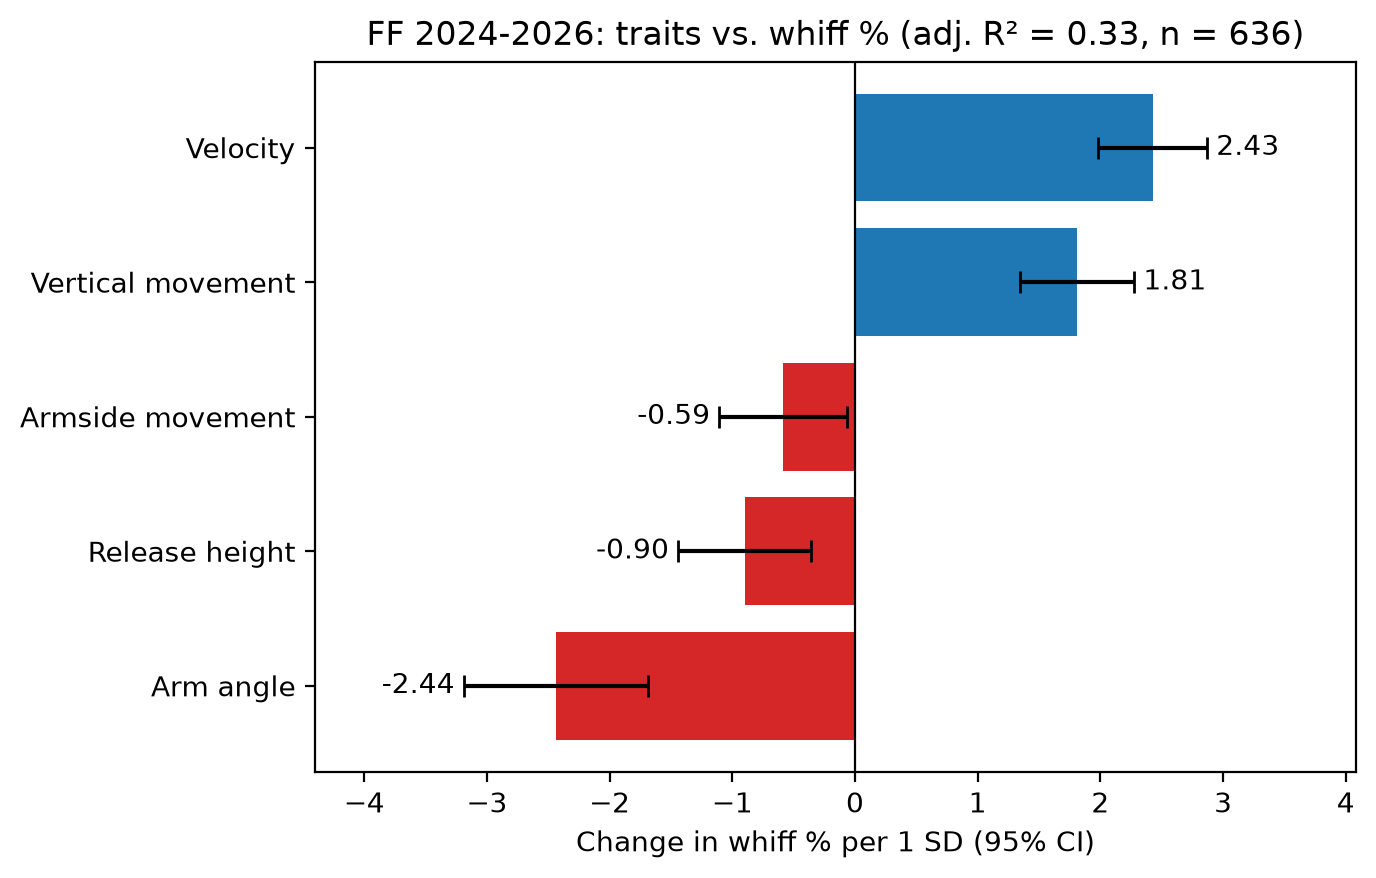

SI None -> whiff_percent  (n = 325)
                           coef   ci_lo   ci_hi  p_value
avg_speed                1.9073  1.4514  2.3632   0.0000
ball_angle               0.3870 -0.8764  1.6504   0.5482
release_ball_z          -0.3057 -1.1198  0.5085   0.4618
break_x_arm             -1.5080 -2.1740 -0.8420   0.0000
pitcher_break_z_induced -0.5996 -1.7058  0.5067   0.2881
Adjusted R^2: 0.236
CV typical miss: 3.7686  vs. guessing the mean: 4.2843



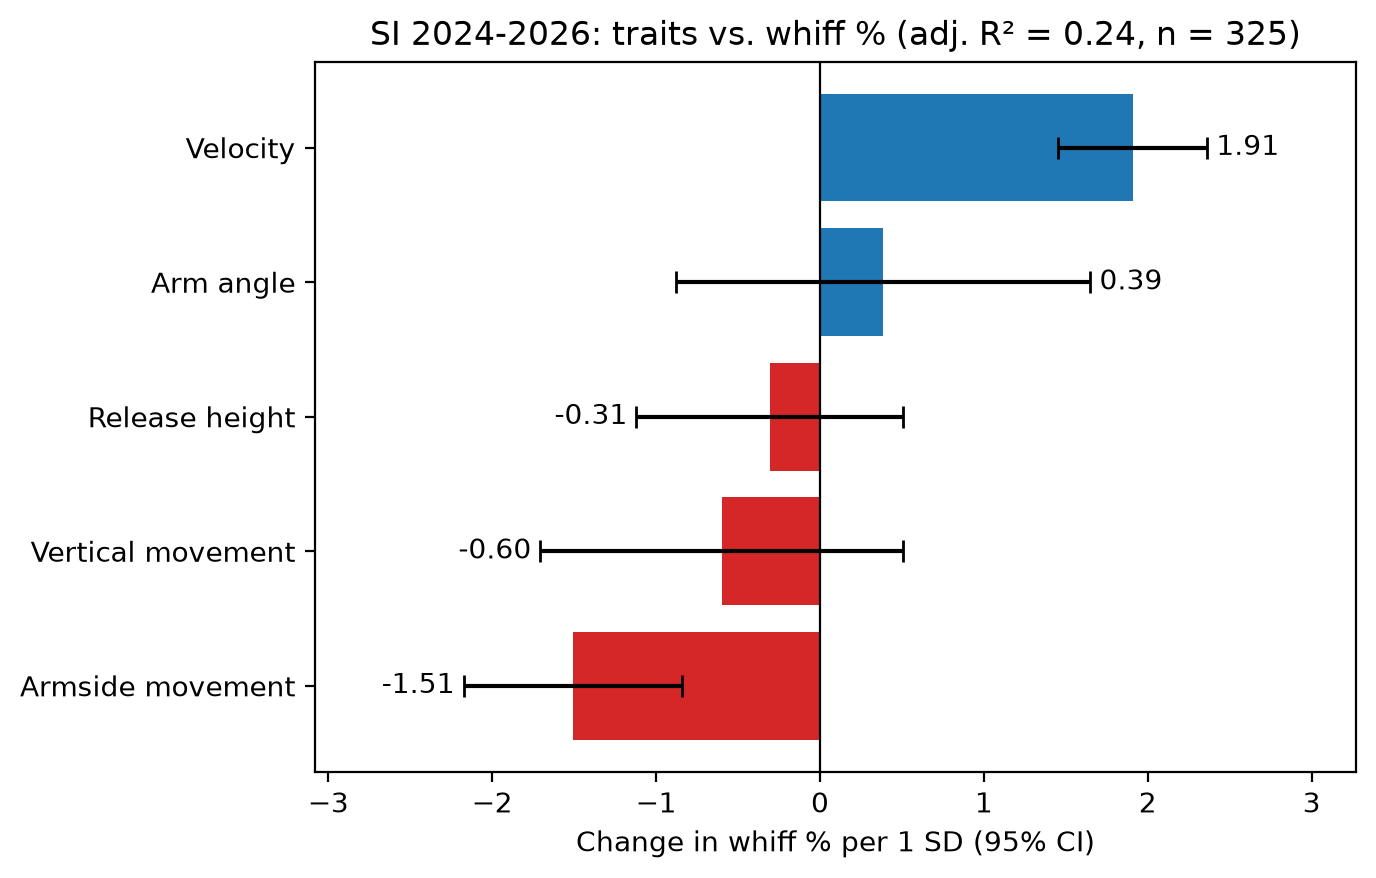

SL None -> whiff_percent  (n = 284)
                           coef   ci_lo   ci_hi  p_value
avg_speed                1.1758  0.2369  2.1147   0.0141
ball_angle              -1.4330 -2.9584  0.0924   0.0656
release_ball_z           0.8061 -0.7142  2.3263   0.2987
break_x_arm             -0.0841 -0.9627  0.7944   0.8511
pitcher_break_z_induced -3.0279 -3.9112 -2.1446   0.0000
Adjusted R^2: 0.150
CV typical miss: 7.4428  vs. guessing the mean: 7.9184



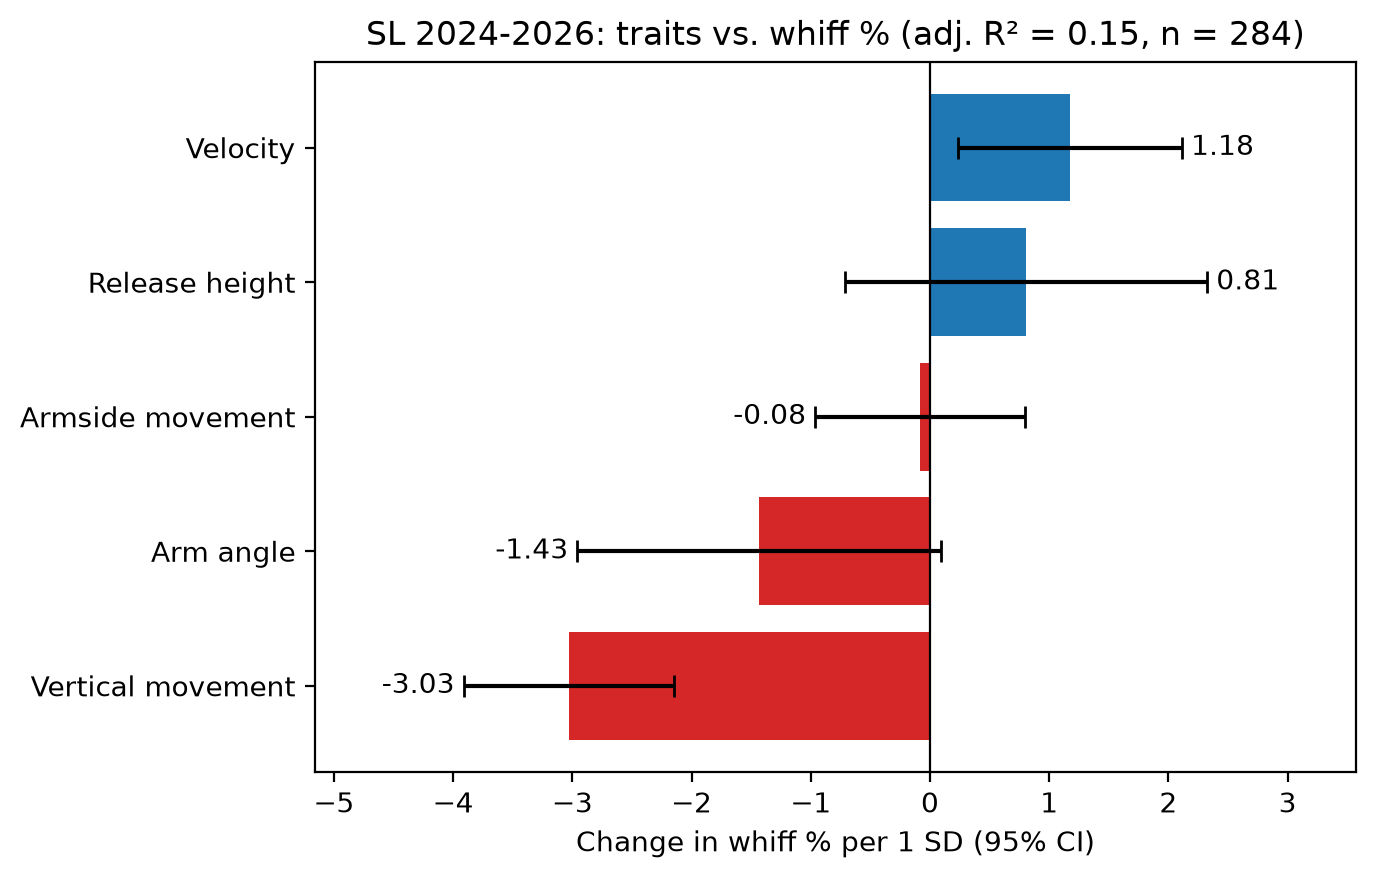

ST None -> whiff_percent  (n = 158)
                           coef   ci_lo   ci_hi  p_value
avg_speed                1.3745  0.0479  2.7011   0.0423
ball_angle               0.5515 -1.3978  2.5007   0.5792
release_ball_z          -0.3468 -2.1843  1.4907   0.7114
break_x_arm              1.7019  0.3798  3.0240   0.0116
pitcher_break_z_induced -0.8495 -2.0969  0.3979   0.1820
Adjusted R^2: 0.131
CV typical miss: 6.8441  vs. guessing the mean: 7.0087



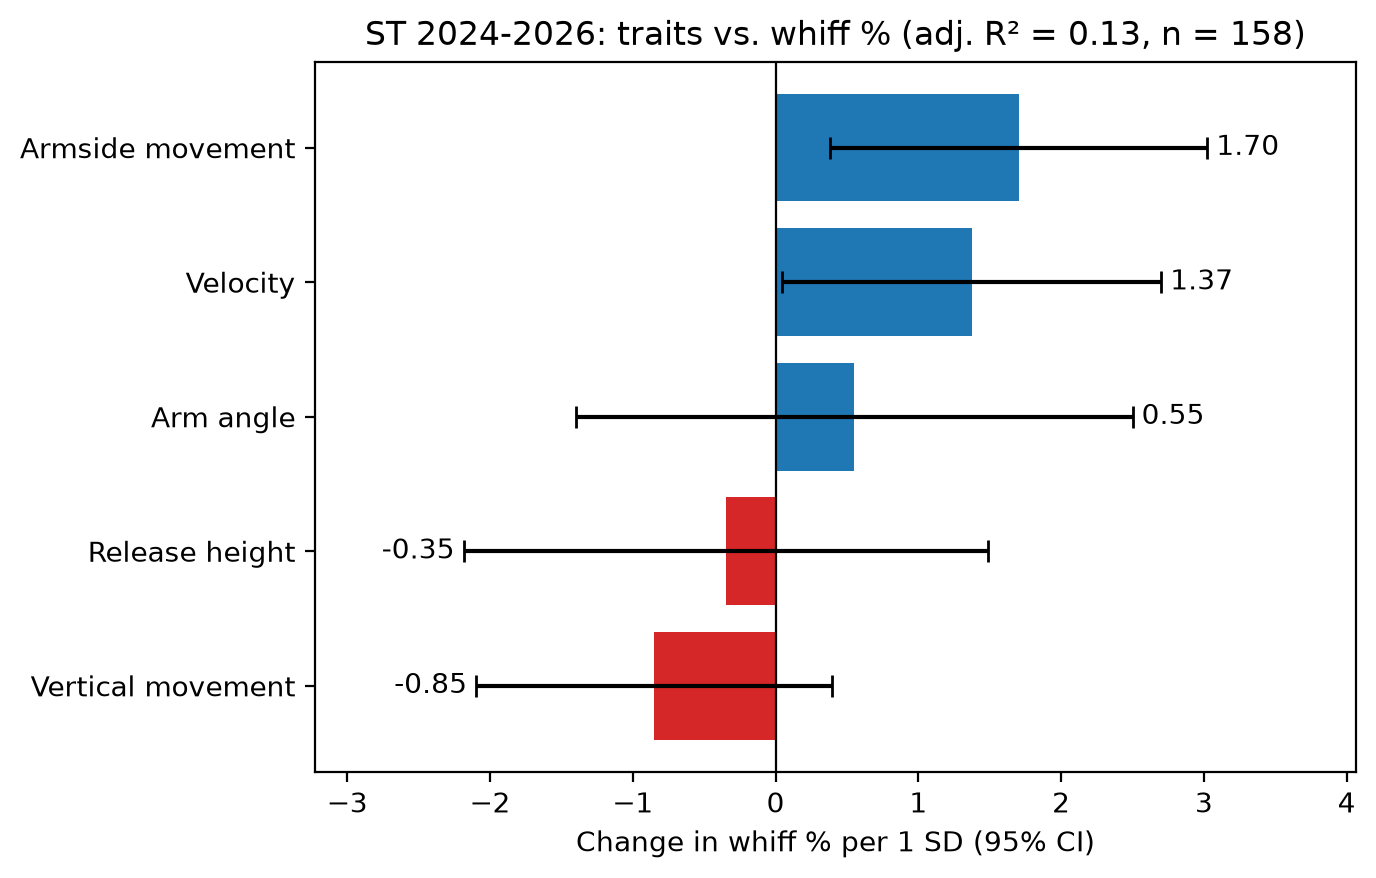

CH None -> whiff_percent  (n = 225)
                           coef   ci_lo   ci_hi  p_value
avg_speed                0.2821 -0.8323  1.3965   0.6198
ball_angle               2.6815  0.9235  4.4396   0.0028
release_ball_z           0.1883 -1.5376  1.9143   0.8306
break_x_arm              0.5460 -0.7461  1.8380   0.4076
pitcher_break_z_induced -0.1388 -1.7316  1.4539   0.8644
Adjusted R^2: 0.094
CV typical miss: 7.3440  vs. guessing the mean: 7.6800



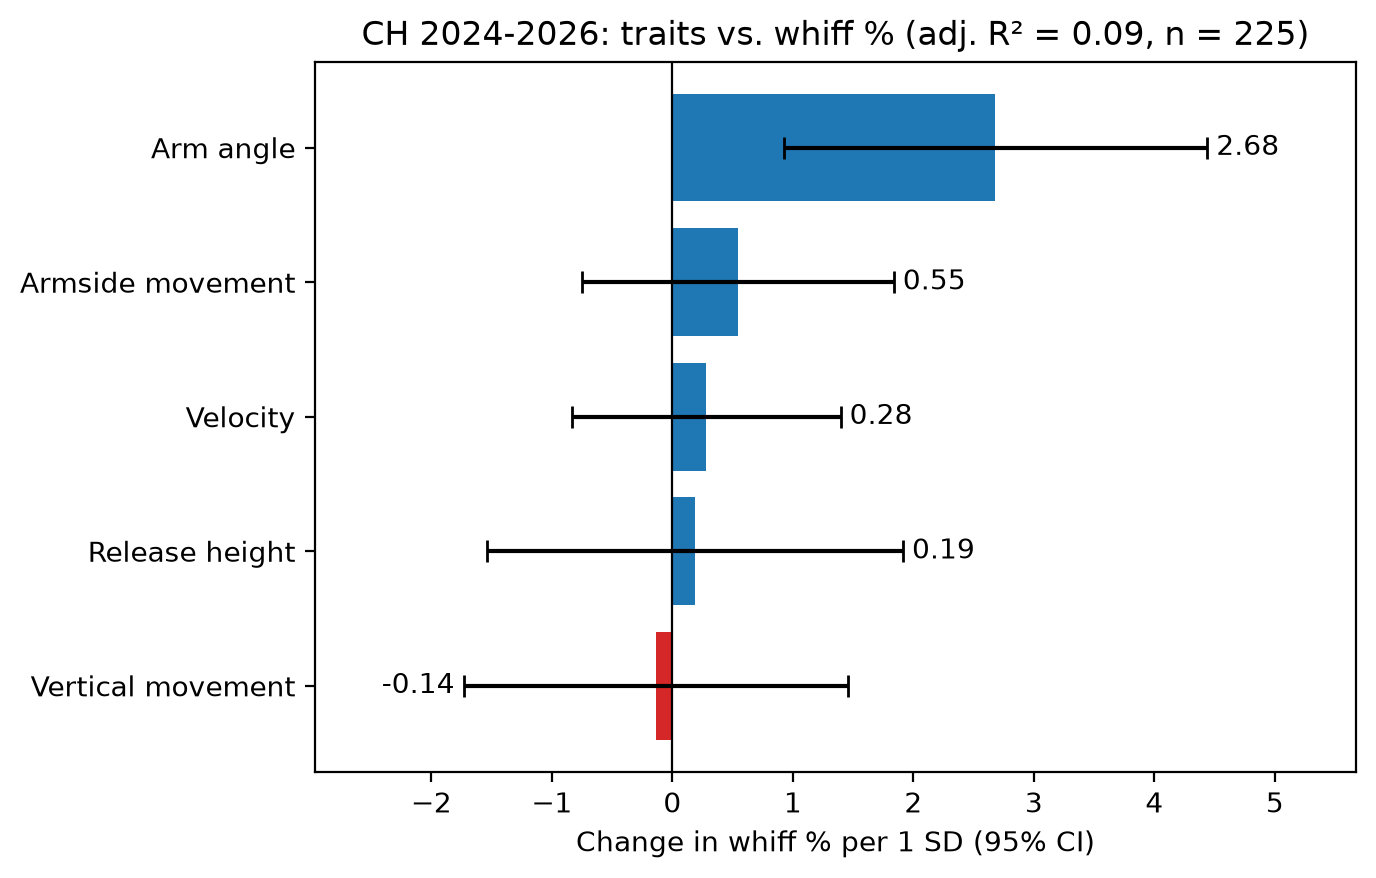

CU None -> whiff_percent  (n = 159)
                           coef   ci_lo   ci_hi  p_value
avg_speed                2.4029  1.0960  3.7099   0.0003
ball_angle              -1.2896 -3.4223  0.8432   0.2360
release_ball_z          -0.7476 -2.3923  0.8972   0.3730
break_x_arm             -0.1788 -2.1141  1.7565   0.8563
pitcher_break_z_induced -0.7427 -2.4937  1.0082   0.4057
Adjusted R^2: 0.116
CV typical miss: 6.9384  vs. guessing the mean: 7.3610



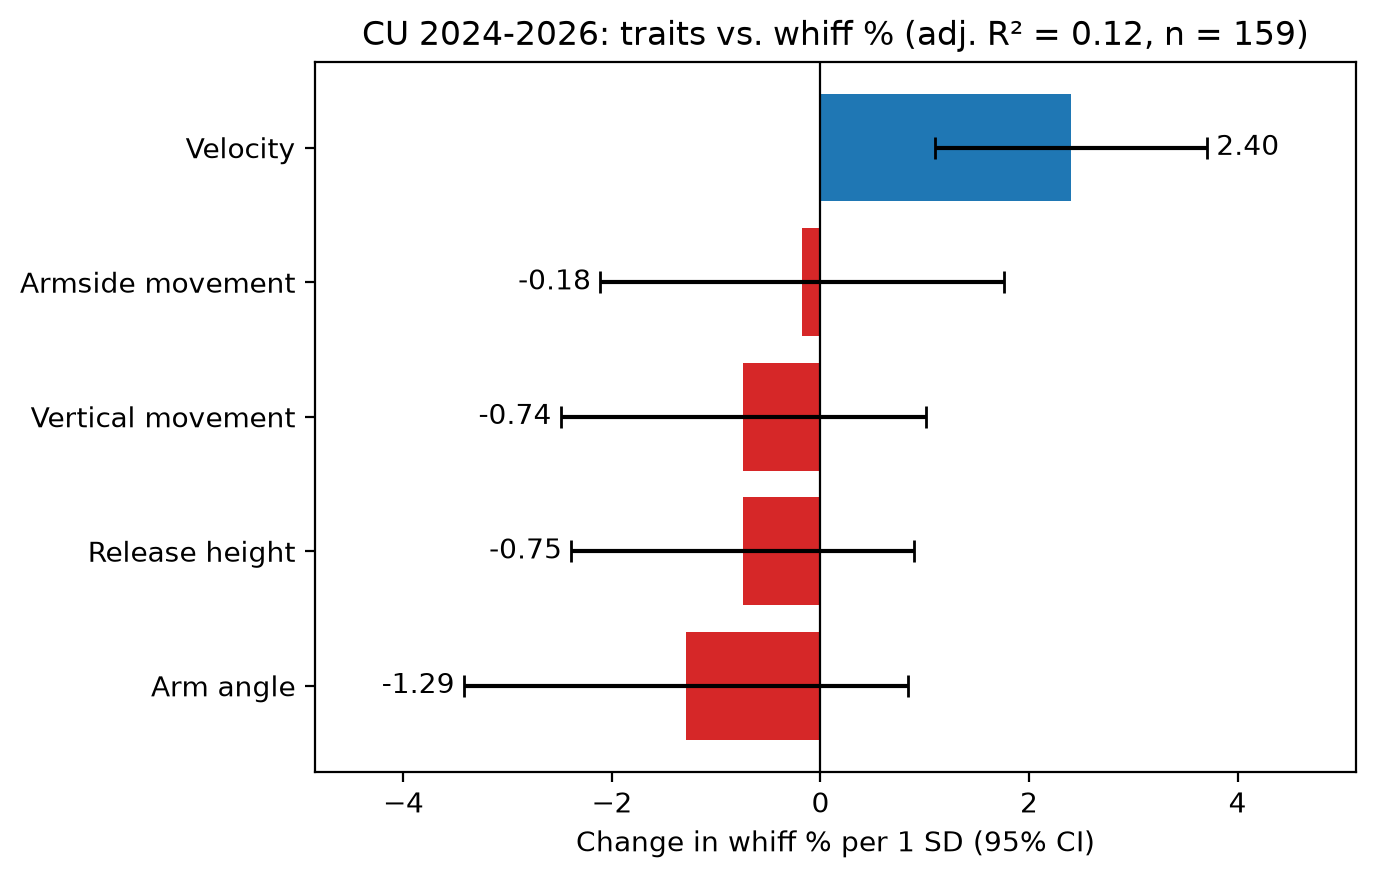

FC None -> whiff_percent  (n = 176)
                           coef   ci_lo   ci_hi  p_value
avg_speed                0.4044 -0.3141  1.1228   0.2700
ball_angle              -0.3623 -1.8232  1.0986   0.6269
release_ball_z           0.0854 -1.0721  1.2429   0.8850
break_x_arm             -1.5574 -2.9015 -0.2132   0.0232
pitcher_break_z_induced -1.0824 -2.2830  0.1182   0.0772
Adjusted R^2: 0.096
CV typical miss: 5.5459  vs. guessing the mean: 5.6976



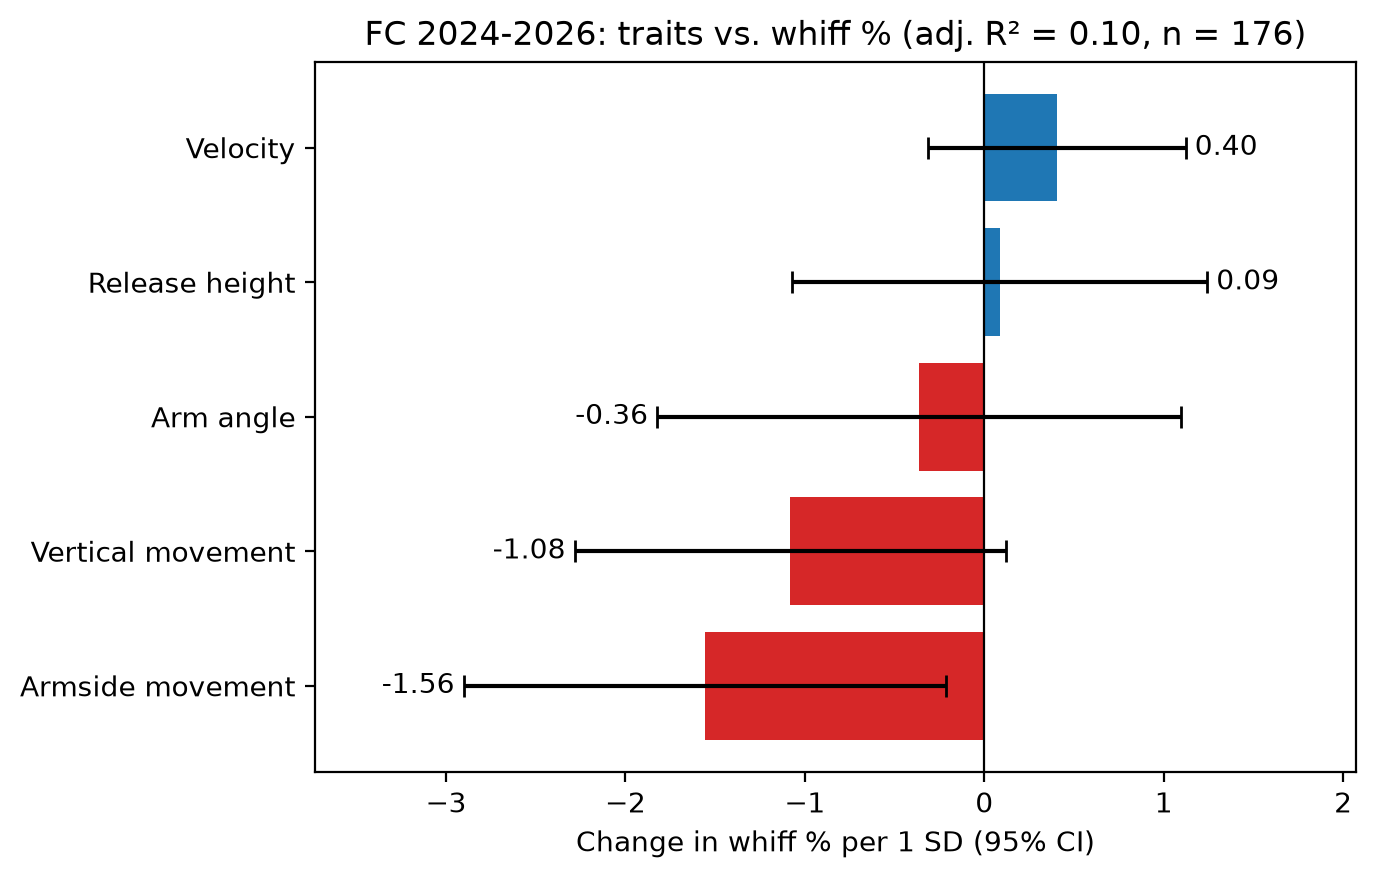

FS None -> whiff_percent  (n = 66)
                           coef   ci_lo   ci_hi  p_value
avg_speed               -1.5204 -3.4463  0.4056   0.1218
ball_angle               1.7320 -1.1128  4.5768   0.2327
release_ball_z          -4.0168 -6.5139 -1.5197   0.0016
break_x_arm             -3.7200 -6.6829 -0.7570   0.0139
pitcher_break_z_induced  1.3044 -0.8872  3.4959   0.2434
Adjusted R^2: 0.296
CV typical miss: 7.4809  vs. guessing the mean: 8.7419



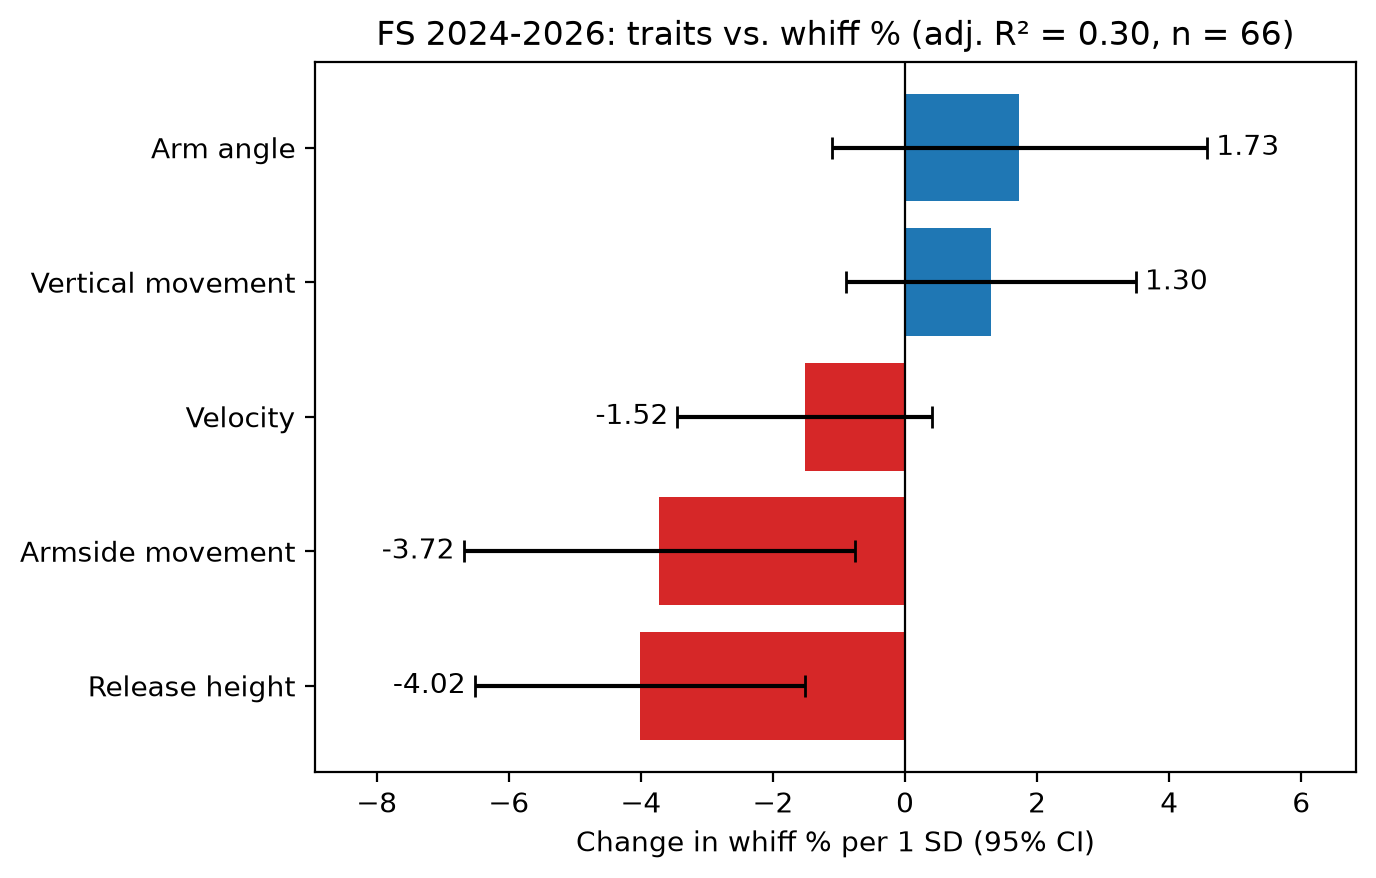

coef  ci_lo  ci_hi  p_value
pitch_type feature                                              
FF         avg_speed                2.427  1.983  2.872    0.000
           ball_angle              -2.437 -3.189 -1.684    0.000
           release_ball_z          -0.900 -1.442 -0.357    0.001
           break_x_arm             -0.587 -1.107 -0.067    0.027
           pitcher_break_z_induced  1.813  1.348  2.278    0.000
SI         avg_speed                1.907  1.451  2.363    0.000
           ball_angle               0.387 -0.876  1.650    0.548
           release_ball_z          -0.306 -1.120  0.508    0.462
           break_x_arm             -1.508 -2.174 -0.842    0.000
           pitcher_break_z_induced -0.600 -1.706  0.507    0.288
SL         avg_speed                1.176  0.237  2.115    0.014
           ball_angle              -1.433 -2.958  0.092    0.066
           release_ball_z           0.806 -0.714  2.326    0.299
           break_x_arm             -0.084 -0.963  0.794    0.851
           pitcher_break_z_induced -3.028 -3.911 -2.145    0.000
ST         avg_speed                1.374  0.048  2.701    0.042
           ball_angle               0.551 -1.398  2.501    0.579
           release_ball_z          -0.347 -2.184  1.491    0.711
           break_x_arm              1.702  0.380  3.024    0.012
           pitcher_break_z_induced -0.850 -2.097  0.398    0.182
CH         avg_speed                0.282 -0.832  1.397    0.620
           ball_angle               2.682  0.923  4.440    0.003
           release_ball_z           0.188 -1.538  1.914    0.831
           break_x_arm              0.546 -0.746  1.838    0.408
           pitcher_break_z_induced -0.139 -1.732  1.454    0.864
CU         avg_speed                2.403  1.096  3.710    0.000
           ball_angle              -1.290 -3.422  0.843    0.236
           release_ball_z          -0.748 -2.392  0.897    0.373
           break_x_arm             -0.179 -2.114  1.757    0.856
           pitcher_break_z_induced -0.743 -2.494  1.008    0.406
FC         avg_speed                0.404 -0.314  1.123    0.270
           ball_angle              -0.362 -1.823  1.099    0.627
           release_ball_z           0.085 -1.072  1.243    0.885
           break_x_arm             -1.557 -2.902 -0.213    0.023
           pitcher_break_z_induced -1.082 -2.283  0.118    0.077
FS         avg_speed               -1.520 -3.446  0.406    0.122
           ball_angle               1.732 -1.113  4.577    0.233
           release_ball_z          -4.017 -6.514 -1.520    0.002
           break_x_arm             -3.720 -6.683 -0.757    0.014
           pitcher_break_z_induced  1.304 -0.887  3.496    0.243

In [210]:
# Pick features, then run every pitch type (types with < min_n pitchers are skipped)
features = ['avg_speed', 'ball_angle', 'release_ball_z','break_x_arm','pitcher_break_z_induced']

results = run_pitch_types(data, ['FF', 'SI', 'SL', 'ST', 'CH', 'CU', 'FC', 'FS'],
                          features, target='whiff_percent', year=None, min_n=40)

# Single pitch type / other target / pooled years:
# res = fit_pitch_model(data, 'SL', features, target='est_woba', year=[2025, 2026])
# summarize(res); plot_pitch_model(res); plt.show()

# All coefficients side by side
coef_table(results).round(3)


# Testing 

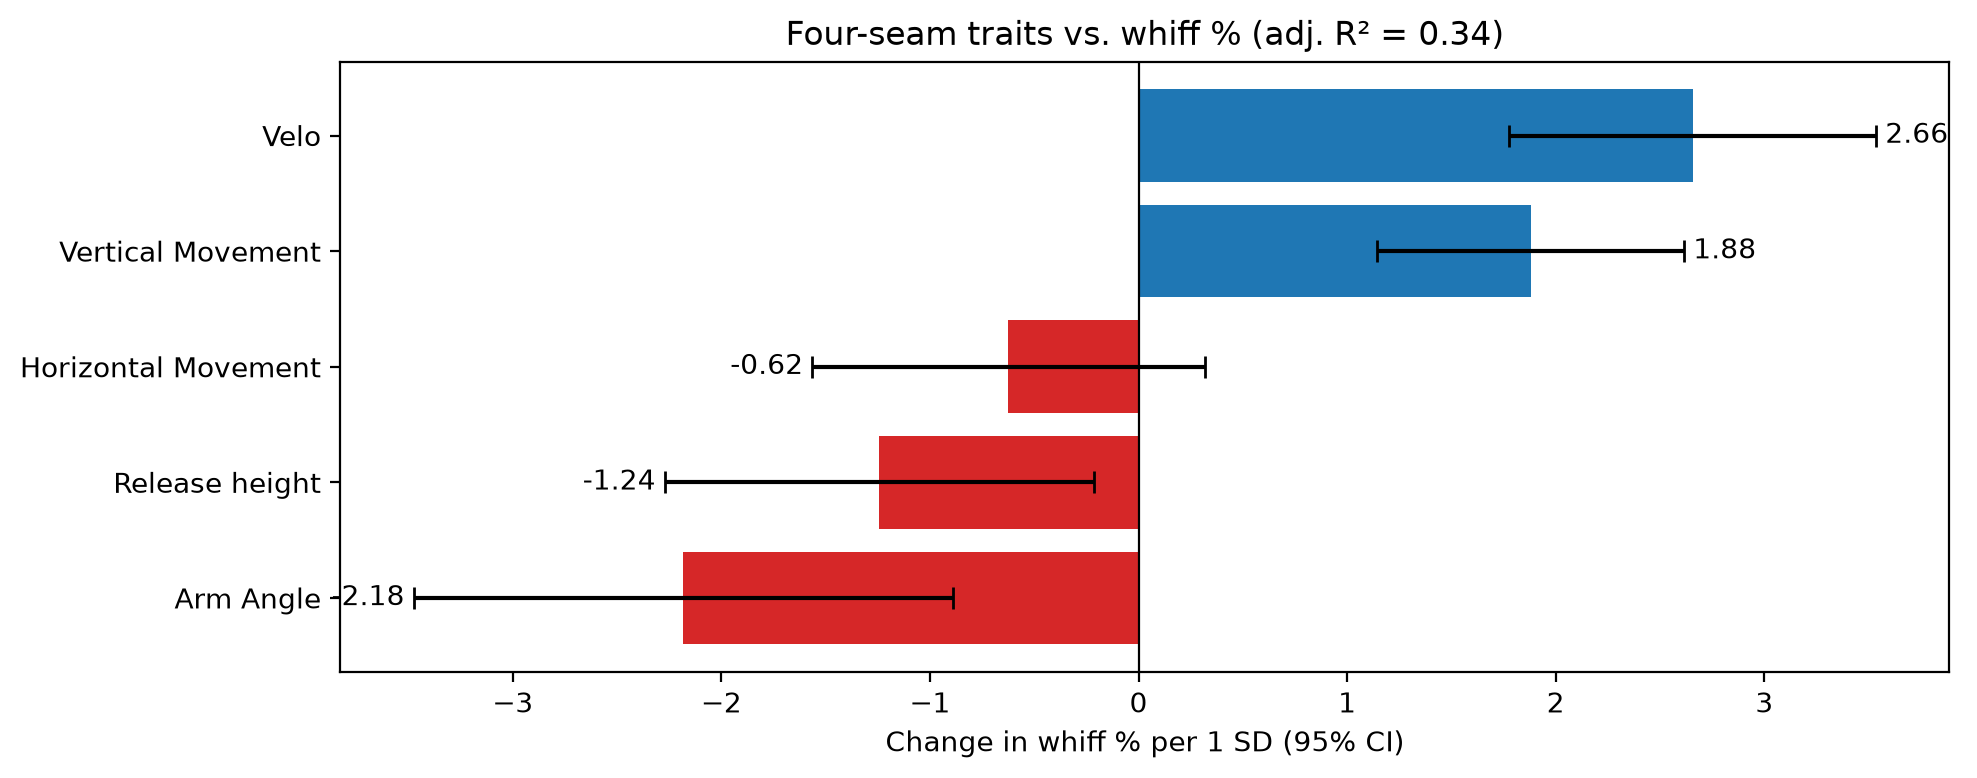

In [140]:
import matplotlib.pyplot as plt

labels = {
    'avg_speed': 'Velo',
    'ball_angle': 'Arm Angle',
    'release_ball_z': 'Release height',
    'pitcher_break_x': 'Horizontal Movement',
    'pitcher_break_z_induced': 'Vertical Movement',
}

weights = coefs.rename(labels).sort_values()
ci = ci.rename(index=labels).loc[weights.index]
err = [weights - ci['lo'], ci['hi'] - weights]   # distance from estimate to each bound

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['tab:blue' if c > 0 else 'tab:red' for c in weights]
ax.barh(weights.index, weights.values, color=colors, xerr=err, capsize=4, ecolor='black')
ax.axvline(0, color='black', linewidth=0.8)

for i, (c, hi, lo) in enumerate(zip(weights, ci['hi'], ci['lo'])):
    x = hi if c >= 0 else lo   # put the label past the end of the error bar
    ax.text(x, i, f' {c:.2f} ', va='center', ha='left' if c >= 0 else 'right')

ax.set_xlabel('Change in whiff % per 1 SD (95% CI)')
ax.set_title(f'Four-seam traits vs. whiff % (adj. R² = {r2_adj:.2f})')
plt.tight_layout()
plt.show()

# 2026 with raw movement